# Operazione di convoluzione

Si definisce la convoluzione su un'immagine $L \in \mathbb{R}^{H \times W}$ contro una maschera $M \in \mathbb{R}^{n \times n}$, dove $n < H$, $n < W$ e $n = 2m + 1$:

$$
(L * M)_{ij} = \sum_{a = -m}^m \sum_{b = -m}^m L_{i - a, j - b} M_{ab}
$$

NB: $L * M \in \mathbb{R}^{(H-n+1) \times (W - n+1)}$


Ad esempio, per $n = 3$:
$$
\begin{align*}
(L * M)_{ij} & = & L_{i - 1, j - 1} \cdot M_{1, 1} & + & L_{i - 1, j} \cdot M_{1, 0} & + & L_{i - 1, j + 1} \cdot M_{1, -1} + \\
& + & L_{i , j - 1} \cdot M_{0, 1} & + & L_{i , j} \cdot M_{0, 0} & + & L_{i , j + 1} \cdot M_{0, -1} +\\
& + & L_{i + 1, j - 1} \cdot M_{-1, 1} & + & L_{i + 1, j} \cdot M_{-1, 0} & + & L_{i + 1, j + 1} \cdot M_{-1, -1} 
\end{align*}
$$


In [18]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [19]:
def apply_mask(img, mask):
    height = img.shape[0] - mask.shape[0] + 1
    width = img.shape[1] - mask.shape[1] + 1

    result = np.zeros((height, width))

    kernel_size = mask.shape[0]

    for i in range(height):
        for j in range(width):
            mat = img[ i:i+kernel_size, j:j+kernel_size]

            result[i, j] = np.sum(np.multiply(mat, mask))

    return result

### Filtro di Sobel e filtro Laplaciano

Definire il filtro di Sobel e il filtro Laplaciano.

In [ ]:
img = mpimg.imread('img/1.jpg')

img_luminanza = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]

mask_x = np.array([
                [-1, -2, -1], 
                [0, 0, 0], 
                [1, 2, 1]])

mask_y = np.array([
                [-1, 0, 1], 
                [-2, 0, 2], 
                [-1, 0, 1]])

img_x = apply_mask(img_luminanza, mask_x)

img_y = apply_mask(img_luminanza, mask_y)

img_sobel = np.abs(img_x) + np.abs(img_y)

mask_laplace = np.array([[0, 1, 0], 
                         [1, -4, 1],
                         [0, 1, 0]])

img_laplace = apply_mask(img_luminanza, mask_laplace)


Caricare un'immagine e applicare i filtri di Sobel e Laplaciano su di essa.

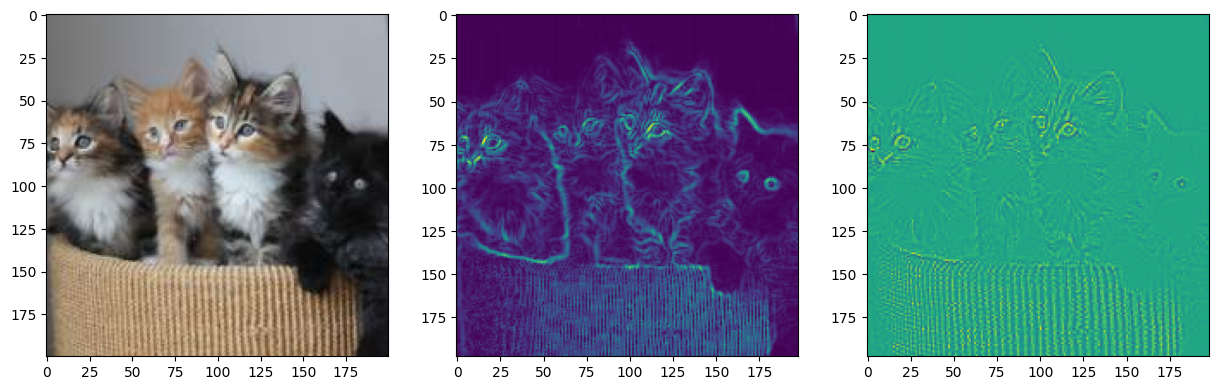

In [27]:
img = mpimg.imread('img/1.jpg')

img_luminanza = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]

img_x = apply_mask(img_luminanza, mask_x)

img_y = apply_mask(img_luminanza, mask_y)

img_sobel = np.abs(img_x) + np.abs(img_y)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(img)
axs[1].imshow(img_sobel)
axs[2].imshow(apply_mask(img_luminanza, mask_laplace))

### Filtri di smoothing

Definire un filtro di media $5 \times 5$. Applicarlo poi alla immagine precedente.

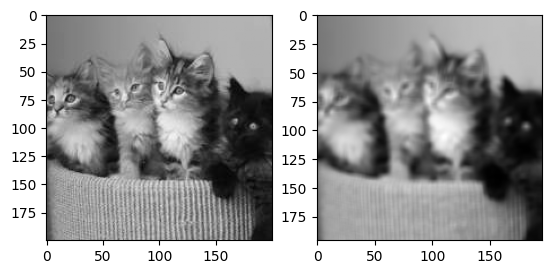

In [28]:
mask_media = np.array([
                    [1/25, 1/25, 1/25, 1/25, 1/25],
                    [1/25, 1/25, 1/25, 1/25, 1/25],
                    [1/25, 1/25, 1/25, 1/25, 1/25],
                    [1/25, 1/25, 1/25, 1/25, 1/25],
                    [1/25, 1/25, 1/25, 1/25, 1/25]
                      ])

img_media = apply_mask(img_luminanza, mask_media)

fig, axs = plt.subplots(1, 2)

axs[0].imshow(img_luminanza, cmap="gray")
axs[1].imshow(img_media, cmap="gray")

Definire un filtro Gaussiano $5 \times 5$. Applicarlo poi alla immagine precedente.

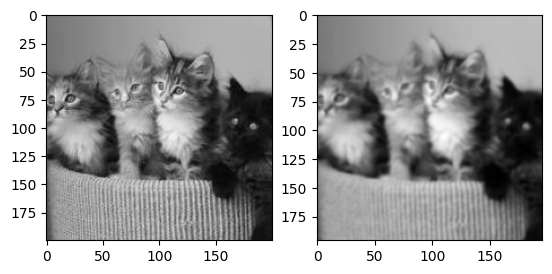

In [30]:
mask_gauss = np.zeros((5, 5))

const_norm = 1 / (2 * np.pi)

def gauss(i, j):
    return const_norm * np.exp( - (i**2 + j**2) / 2)

for i in range(-2, 3):
    for j in range(-2, 3):
        mask_gauss[i + 2, j + 2] = gauss(i, j)

img_gauss = apply_mask(img_luminanza, mask_gauss)

fig, axs = plt.subplots(1, 2)

axs[0].imshow(img_luminanza, cmap="gray")
axs[1].imshow(img_gauss, cmap="gray")

Definire i filtri di minimo e massimo, e il filtro mediano. In che cosa si differenziano rispetto ai filtri precedenti?